# Electrification of Rotterdam Port

# Project Group - 21

Members:

*   Magdalini Karataraki
*   Yiying Sandra Zhu Zhou
*   Stella Nestori
*   Fernando Quiros
*   Andrea De Felice

# Github Repository

https://github.com/sandrazhu21/-TIL6022-TIL-Python-Programming-Group-21

# Introduction


## Context & relevance

The transition towards more sustainable transport systems is an important part of addressing climate change and reducing greenhouse gas emissions. In the European Union, heavy-duty vehicles, including trucks, buses and coaches, are responsible for more than 25% of road transport greenhouse gas emissions, despite representing only about 2% of vehicles on EU roads (European Commission, 2026). Furthermore, transport activity is expected to increase, therefore reducing the environmental impact of transport has become an important challenge for the transport sector (European Environment Agency, 2026).  

One potential approach to reducing these emissions is the electrification of heavy-duty vehicles. Replacing conventional diesel trucks with electric alternatives can contribute to the decarbonization of freight transport. However, the transition involves more than simply replacing one type of vehicle with another. The integration of electric trucks into existing transport operations also requires suitable charging infrastructure to ensure that vehicles have sufficient energy to perform their scheduled duties. The availability, location, and charging capacity of infrastructure therefore play an important role in determining whether electric trucks can be practically integrated into daily logistics operations.  

In particular, charging opportunities need to align with the operational schedules of freight transport. Trucks may be able to recharge between working days, but this may not always provide sufficient energy for more demanding daily operations. Charging during scheduled stops, such as loading and unloading periods, could offer an additional opportunity to replenish the battery. The feasibility of this depends on how well charging opportunities fit within the existing transport schedules.

These considerations are particularly relevant in port environments, where freight transport connects maritime activities with inland networks. In ports, there are substantial truck movements between terminals, distribution centers and other destinations, which makes electrification of trucks operating in and around ports an important consideration. In this context, the Port of Rotterdam (PoR) can serve as a relevant case for examining this.  As a major logistics hub, it accommodates different types of hinterland truck operations that vary in distance, frequency, and daily schedules. According to Smart Freight Centre (2024), approximately 55% of the port's hinterland container transport is carried by trucks, resulting in around 10,000 truck movements to and from the port each day. These movements involve a variety of transport distances, with some trucks performing multiple relatively short trips and others undertaking longer journeys. The report also indicates that approximately 74% of truck trips to and from the port fall within 250km. This illustrates the diversity of truck operations in the port area and suggests that different operational profiles may have different energy requirements and charging needs.  

The feasibility of electrifying these operations depends on the relationship between vehicle energy consumption, battery capacity, and the availability of charging opportunities. For trucks that return to their depot at the end of the working day, depot charging can provide a relatively straightforward solution, as vehicles can recharge during overnight parking. However, for trucks undertaking longer distances or multiple trips within a single working day, overnight charging may not always provide sufficient energy to complete the required activities. In such cases, additional charging during the working day may be necessary (Volvo Trucks, 2021).

An alternative is opportunity charging, in which trucks recharge during periods when they are already stationary as part of their normal operation. For port-related freight transport, these opportunities may occur at loading and unloading locations, distribution centers or truck parking facilities. By using existing dwell periods for charging, vehicles may replenish part of their battery without requiring additional stops or substantially changing their operational schedules. However, the amount of energy that can be transferred depends on the duration of the stop, the available charging power, and the vehicle's charging characteristics. Consequently, the practical contribution of opportunity charging needs to be assessed in relation to actual vehicle schedules rather than considering charging power or vehicle range in isolation.  

The development of charging infrastructure in the PoR demonstrates the growing relevance of these charging solutions. For example, in January 2024, a charging station opened at Waalhaven where eight electric trucks can charge simultaneously (Port of Rotterdam Authority, 2024). However, the availability of charging infrastructure does not establish whether electric trucks can meet the energy demands of different transport operations. It is therefore important to examine how different charging strategies perform under varying operations conditions.  

This report investigates the feasibility of electrifying representative truck operations in the PoR by comparing short-, medium-, and long-distance transport profiles. It examines whether these operations can be supported by depot charging alone or whether additional opportunity charging is required during the working day. In addition, analysis considers different opportunity charging power levels to assess their contribution to meeting daily energy requirements. By comparing these scenarios, the report aims to identify the operational conditions under which electric trucks can complete their daily duties and sustain repeatable operations.  



## Research Objective

The objective of this project is to assess the feasibility of electrifying representative truck operations serving the PoR. Specifically, the study investigates which truck duties can be completed using overnight depot charging along and which require additional opportunity charging during scheduled dwell periods. Three operational profiles representing short-, medium-, and long-distance transport are considered to examine how differences in travel distance, number of round trips and available charging opportunities influence charging requirements.  

The analysis considers both the ability of a truck to complete its scheduled daily duty without failing below the minimum battery state of charge (SOC) and its ability to recover its initial SOC before the following day's departure. Based on this objective, the following main research question is formulated:

**For representative short-, medium-, and long-distance truck duties serving the Port of Rotterdam, which can be completed with overnight depot charging alone, and which require additional opportunity charging during scheduled dwell periods at origin and destination?**

To answer the main research question, the following sub questions are addressed:


1.   What are the daily driving energy requirements of the representative short-, medium-, and long-distance truck duties?
2.   Which combinations of operating profile and charging configuration allow the truck to complete its daily duty without falling below the minimum state of charge?
3.   For the configurations that allow completion of the daily duty, is the remaining time before the next departure sufficient to restore the battery to its initial state of charge using depot charging?
4.   How sensitive is duty feasibility to changes in energy consumption, destination dwell time, and port-terminal dwell time?

The geographical scope of this study is limited to representative hinterland truck operations serving the PoR. The PoR is considered the common starting and returning point for the simulated truck duties, while different destinations represent varying transport distances from the port. The operational profiles are divided into three distance categories, which represent selected operating scenarios and are not intended to capture the full diversity of truck movements in the port area, which is outside the scope of this project.

The temporal scope covers one simulated working day, with the same operational duty assumed to repeat every 24 hours.  


# Methodology

## Data Analysis Pipeline  

To determine which truck duties can be completed with overnight depot charging alone and which require opportunity charging, we developed a deterministic, event-based simulation of one working day for representative short, medium, and long-haul electric trucks serving the Port of Rotterdam (PoR). The model tracks the truck's battery through a chronological sequence of driving and dwell events, checking after each event whether the minimum State of Charge (SOC) requirement is respected. It subsequently tests whether the vehicle can recover its energy overnight at the depot before the next duty. By evaluating the three operational profiles in correlation with three alternative charging configurations, the framework establishes nine baseline scenarios to compare different route requirements and charging strategies.

The simulation workflow is initialized by gathering preliminary electric truck operational values from the Smart Freight Centre (2024), defining a nominal battery capacity of 540 kWh, an energy consumption rate of 1.7 kWh/km, and a charging efficiency of 90%. Operational profile parameters establish route distances and trips per day across Short (30 km one-way, 3 trips), Medium (92.5 km one-way, 2 trips), and Long (187.5 km one-way, 1 trip) profiles. The profiles are set as the mean between the distances presented in the report (for short:0-60km, medium: 60-125km, and long:125-250km respectively).

Charging configurations set depot charging power to 150 kW (SFC, 2024) alongside opportunity charging alternatives of 180, and 360 kW based on the available chargers at the selected location of Waalhaven facility (PoR, n.d.). Through Python classes representing electric trucks, operational profiles, and charging options, the model formats input parameters into structured time-step event lists encompassing outbound drives, destination dwells, return drives, and port-terminal dwells.

During simulation execution, energy consumption is tracked as distance multiplied by consumption during driving legs, while battery headroom and charging power limits dictate energy intake during eligible dwell periods based on the following mathematical relations:

battery headroom=maximum stored energy−current stored energy



actual grid energy=min (power * dwell hours, headroom/ efficiency)



battery energy received=actual grid energy* efficiency

The feasibility evaluation assesses whether duties maintain SOC above the 10% safety floor and whether sufficient off-duty hours remain for a full recharge to the upper operational limit (90% absolute SOC / 100% of the usable window) within a strict 24-hour window.

Executing the simulation under the baseline parameter set yields distinct feasibility profiles for each haul type. Short-haul duties consume 306 kWh of driving energy, remaining well within the 432 kWh usable battery window. Depot-only operation completes the shift ending at 33.3% SOC and requires approximately 2.27 hours of depot recharging, fitting comfortably within the 17.25-hour off-duty window, rendering opportunity charging unnecessary.  

Conversely, medium-haul duties require 629 kWh; under a depot-only setup, the first SOC violation occurs on the second outbound drive. However, with 180 kW opportunity charging available across three dwell periods, the battery receives 364.5 kWh, maintaining a minimum operational SOC of approximately 41.0%.  

Lastly, long-haul duties require 637.5 kWh, where a single 45-minute dwell supplied at 180 kW yields 121.5 kWh—insufficient to preserve the safety reserve on the return leg. Scaling opportunity charging to 360 kW supplies 243 kWh during the dwell, securing a minimum SOC of approximately 16.9% and enabling a full depot recharge in about 2.92 hours within a 17-hour off-duty window.

Battery capacity bounds energy uptake; for instance, the short route accepts a cumulative maximum of only 255 kWh of opportunity energy across all five dwells regardless of whether 180 kW or 360 kW chargers are installed, as additional charger power yields no further energy gains once the 90% SOC ceiling is reached. While larger batteries, lower consumption rates, and higher charger power expand technical feasibility, total daily energy balance alone does not guarantee success, because certain configurations fail on intermediate driving legs before a later opportunity charger can be reached.

These scenario results reflect deterministic outcomes under stated assumptions rather than empirical service-performance claims. Charging power and energy consumption per kilometer (1.7 kWh/km) are treated as constant and independent of external factors such as weather, topography, or traffic speeds. Furthermore, opportunity chargers are assumed to be continuously available at every destination and port-terminal dwell without queuing delays, detours, or extra stopping overhead, with all vehicles initiating their shifts at 90% SOC from a centralized depot at the Port of Rotterdam on a strict, repeatable 24-hour cycle. Finally, to address these deterministic constraints and quantify operational vulnerability, the data analysis pipeline incorporates a dual-stage sensitivity analysis: first testing the core simulation model's robustness against fluctuations in energy consumption rates and dwell times and second integrating real-world traffic and flow variability from the DEXTER dataset (NDW, n.d.).

# Results

The simulation of the representative short, medium, and long-distance truck services in the PoR, shows significant differences in daily energy requirements. With the operational parameters given, the short distance profile (total 180 km) requires 306 kWh, in contrast, the medium distance (total 370 km) requires 629 kWh, while the long-distance duty (total 375 km) requires 637.5 kWh. (Total distance was acquired taking into consideration the distance defined multiplied by 2 for the round trip and then multiplied with the given trip to each profile)



The short-distance duty requires less energy than 432 kWh of usable battery energy within the operating SOC range of 10% to 90%, making depot only charging feasible. In contrast, medium, and long-distance duties require 629 kWh and 637.5 kWh, respectively, exceeding the nominal battery capacity (540 kWh) and requiring opportunity charging during daily operations.

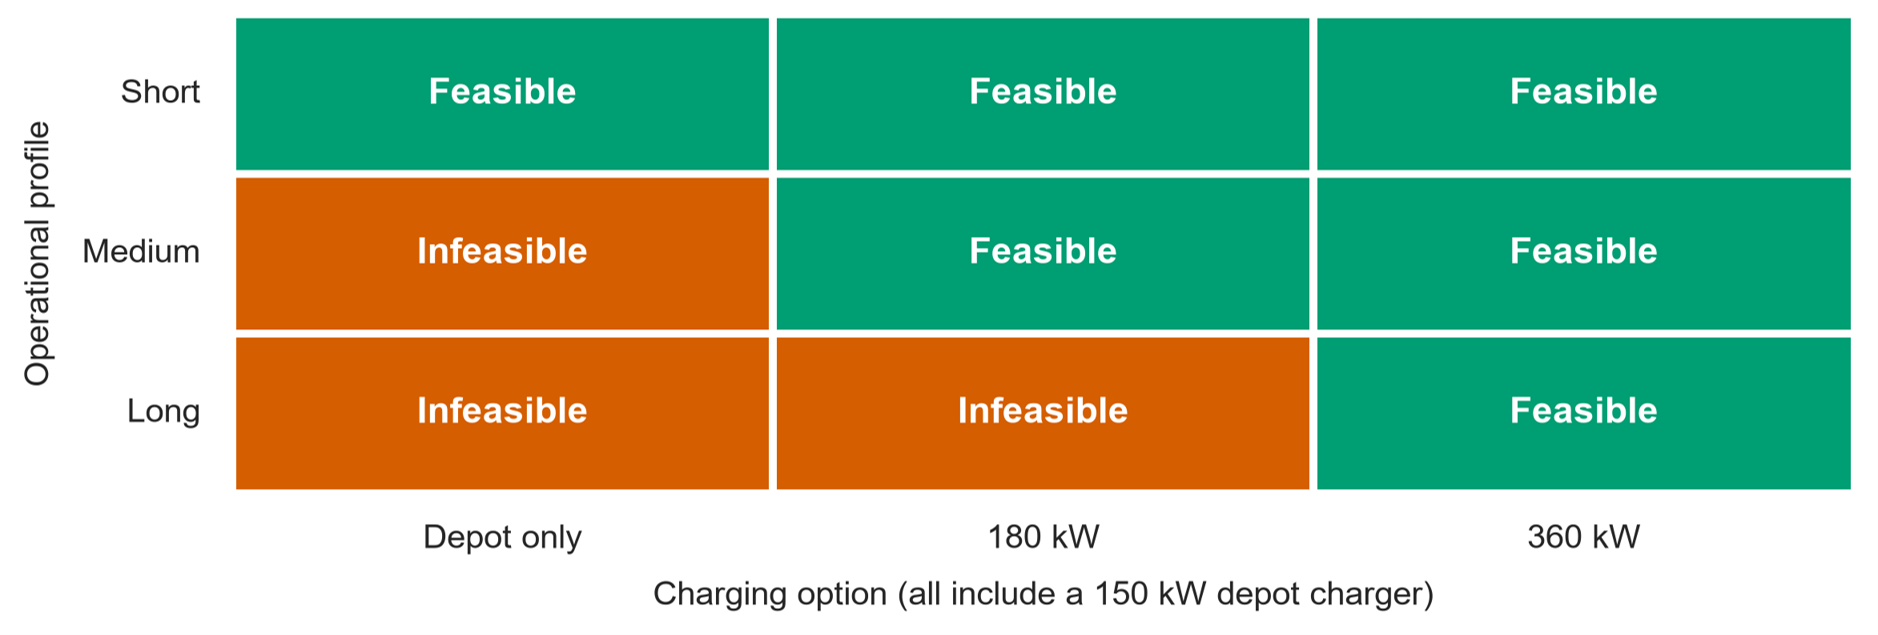

Figure 1. En-route feasibility by operational profile and charging modality

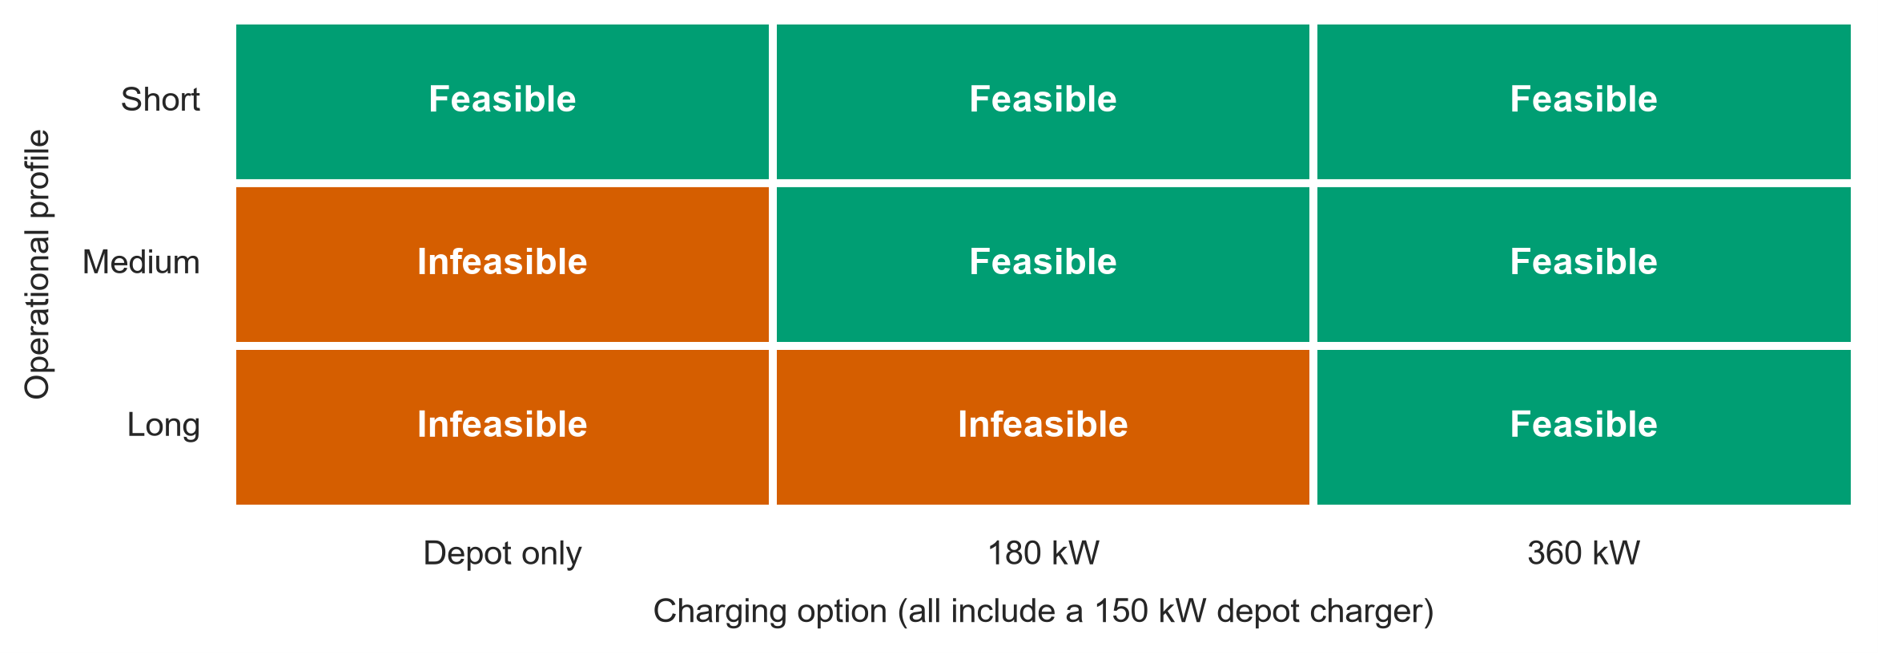

Figure 2. Repeatable daily feasibility with overnight depot charging

Figure 1 and 2 present the en-route and repeatable feasibility across the three operational profiles and charging configurations. The short-distance duty is feasible under all configurations, whereas the medium-distance duty requires at least 180 kW opportunity charging, and the long-distance duty requires 360 kW opportunity charging. Both matrices show identical feasibility results, indicating that all configurations capable of completing the daily duty can also recover their initial SOC through overnight depot charging before the next duty. Therefore, overnight recharging does not introduce an additional feasibility constraint under baseline conditions.

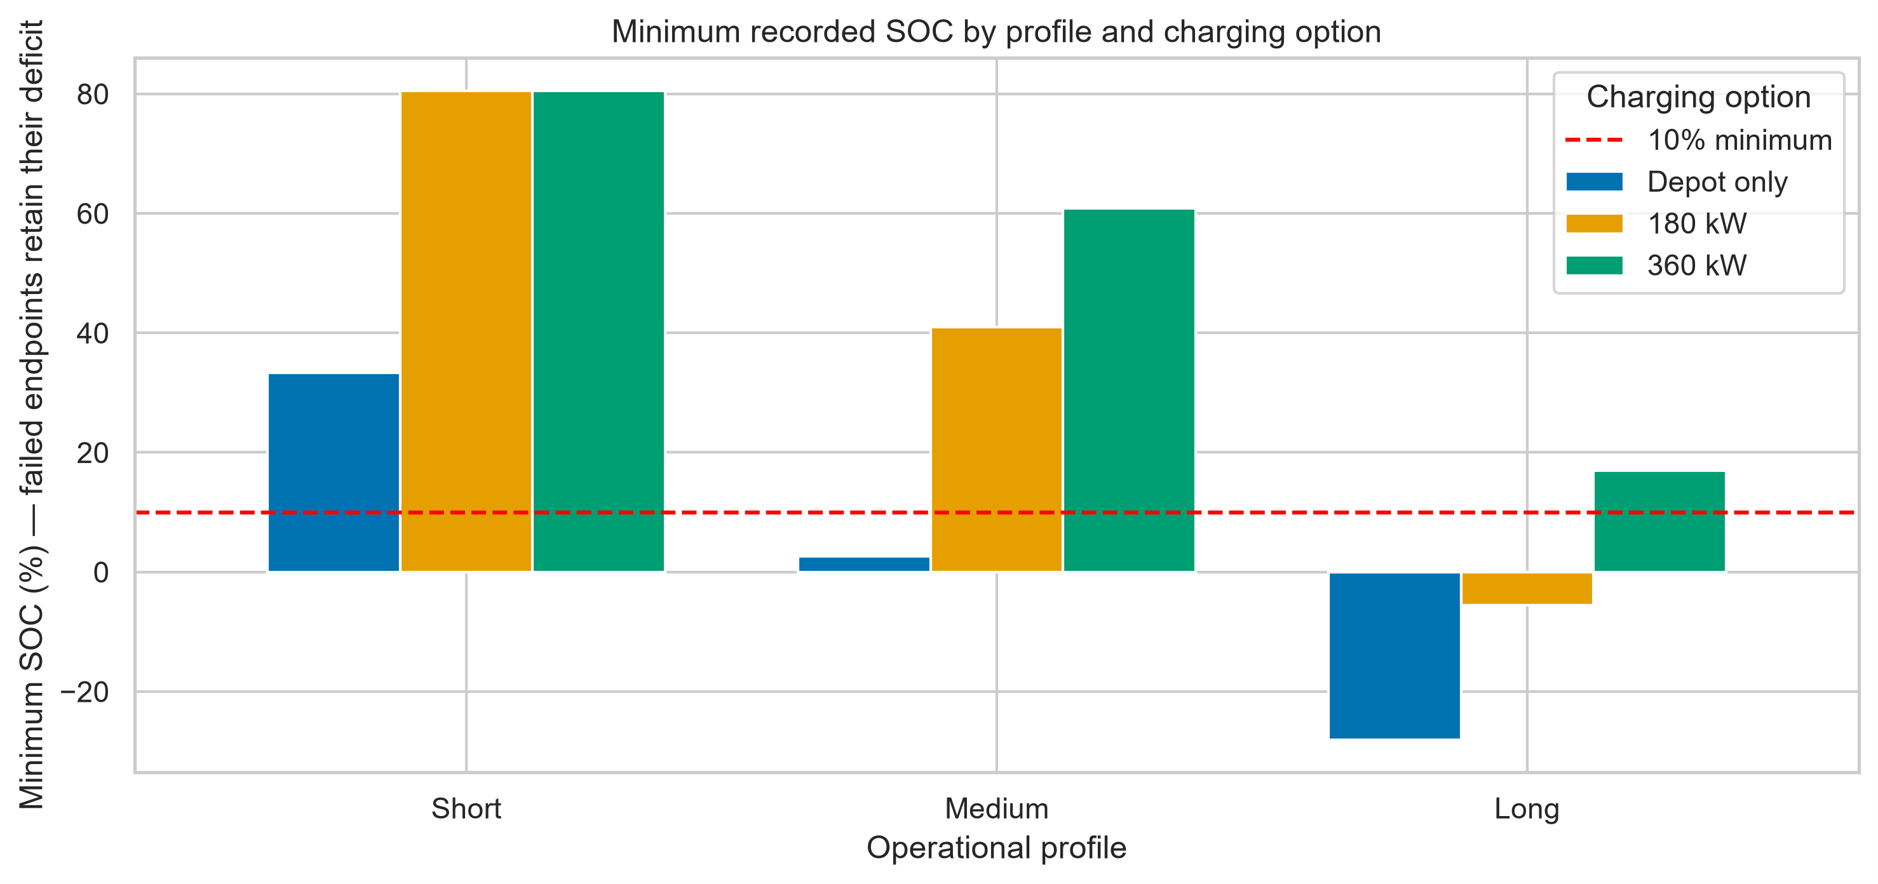

Figure 3. Minimum recorded SOC by profile and charging configuration

Figure 3 compares the minimum recorded SOC for each operational profile and charging configuration, using the feasibility threshold. The short distance duty maintains a minimum SOC of 33.3% with depot-only charging, increasing to approximately 80% with opportunity charging. For the medium-distance duty, the minimum SOC increases to 41.0% with 180 kW charging, and to 60.9% with 360 kW charging. In contrast, the long-distance duty remains below the minimum threshold under depot-only and 180 kW charging, while 360 kW charging maintains a minimum SOC of roughly 16.9% providing a limited margin above the threshold.

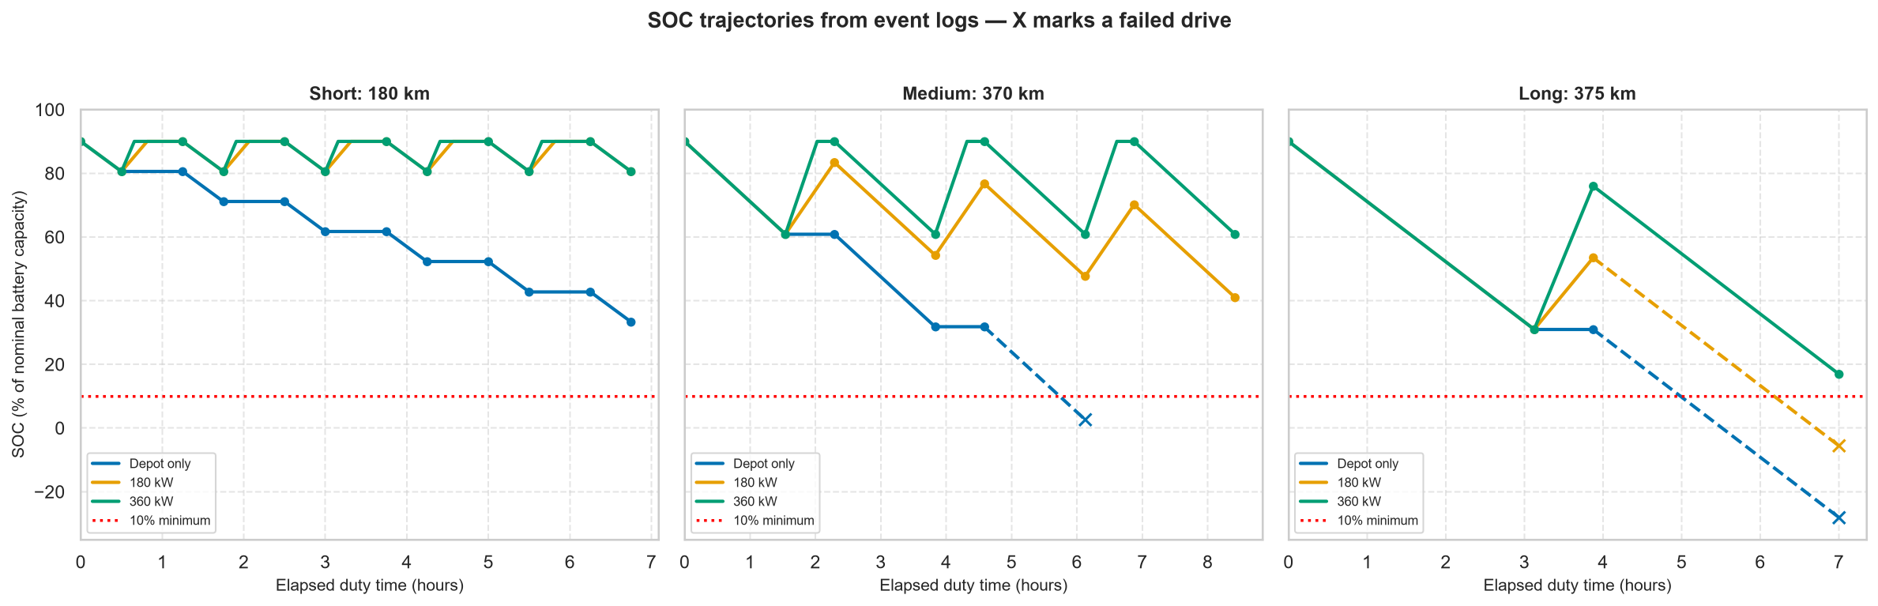

Figure 4. SOC trajectories by daily operations

Figure 4 presents the SOC trajectories throughout the daily operations. Short distance duties remain above the minimum threshold even without opportunity charging. For medium-distance duties, depot-only charging becomes insufficient during the second-round trip, while intermediate charging maintains operational feasibility. Long-distance duties depend on the single destination charging opportunity, where only the 360 kW configuration provides sufficient energy to complete the return trip.

**Sensitivity analysis **



The sensitivity analysis evaluates how changes in energy consumption, destination dwell time, and port terminal dwell time affect the minimum SOC threshold and operational feasibility. A total of 180 simulations were performed, varying one parameter at a time across three operational profiles and three charging configurations. These include 72 simulations for energy consumption and 54 simulations for each dwell time parameter (destination and port-terminal), while the remaining parameters were maintained at their baseline values.



The tested values were selected within predefined minimum and maximum around the baseline assumptions, using equally spaced intervals to assess changes in operational feasibility.


Parameters | Values tested
-------------------|------------------
Energy Consumption  | 0.500, 0.929, 1.357, 1.786, 2.214, 2.643, 3.071, 3.500 kWh/km
Destination dwell time | 0.25, 0.50, 0.75, 1.00, 1.25 and 1.50 hours
Port terminal dwell time | 0.25, 0.50, 0.75, 1.00, 1.25 and 1.50 hours

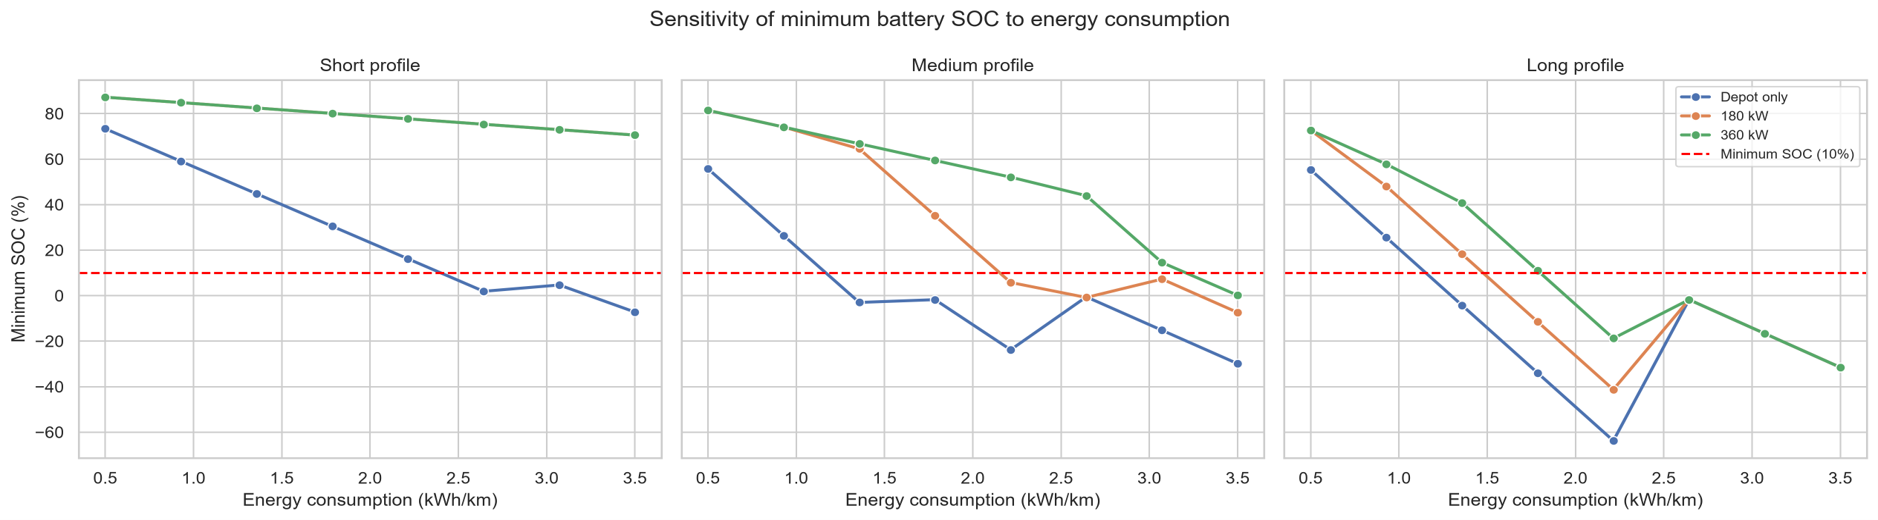

Figure 5. Sensitivity of minimum battery SOC to energy consumption

Figure 5 shows the relationship between energy consumption (kWh/km) and minimum SOC (%) for each operational profile. Higher energy consumption generally reduces the minimum SOC, particularly for medium and long-distance duties. The short-distance duty remains feasible with opportunity charging throughout the tested range, while depot-only charging becomes infeasible at approximately 2.6 kWh/km. For the medium-distance duty, the 180 kW configurations fall below the minimum threshold at approximately 2.2 kWh/km, whereas 360 kW charging maintains feasibility up to approximately 3.1 kWh/km. The long-distance duty is more sensitive, with 360 kW charging falling below the threshold at approximately 2.21 kWh/km.


Additionally, for the medium-distance profile, minor anomalies or fluctuations in minimum SOC occur because the simulation terminates immediately upon breaching the safety threshold. Consequently, a configuration experiencing rapid depletion may trigger an early cutoff, registering a slightly higher final minimum SOC than a schedule that ran longer and bled closer to the floor before failing.

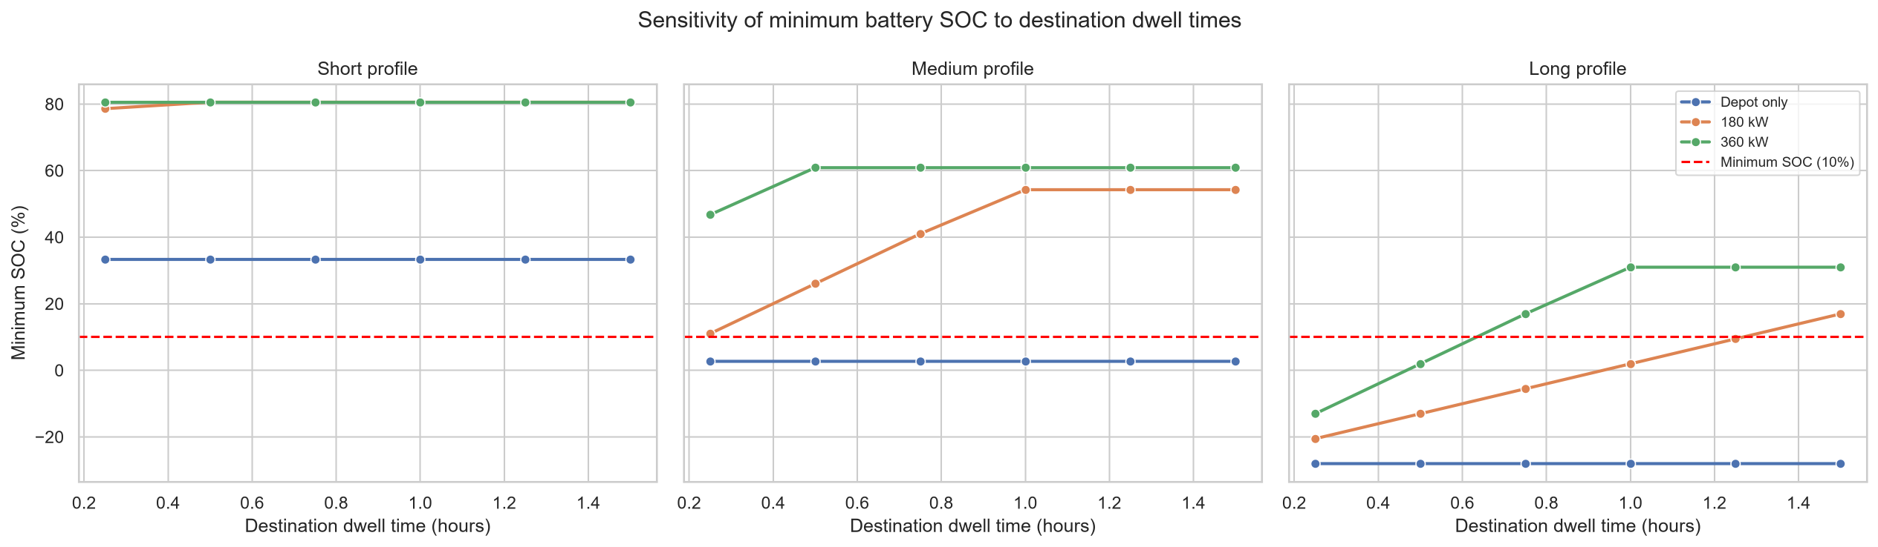

Figure 6. Sensitivity of minimum battery SOC to destination dwell time.

Figure 6 illustrates how minimum SOC changes as destination dwell time increases from 0.25 to 1.5 hours. For short-distance duties, the minimum SOC remains above 30% with depot only charging and approximately 80% with opportunity charging. For medium-distance duties, 360 kW charging reaches approximately 61% minimum SOC with 0.5-hour dwell, while 180 kW charging increases from approximately 11% to 54.3% as dwell time increases. For long-distance duties, 360 kW charging becomes feasible with approximately 0.75 hour of destination dwell, whereas 180 kW charging requires approximately 1.5 hours.

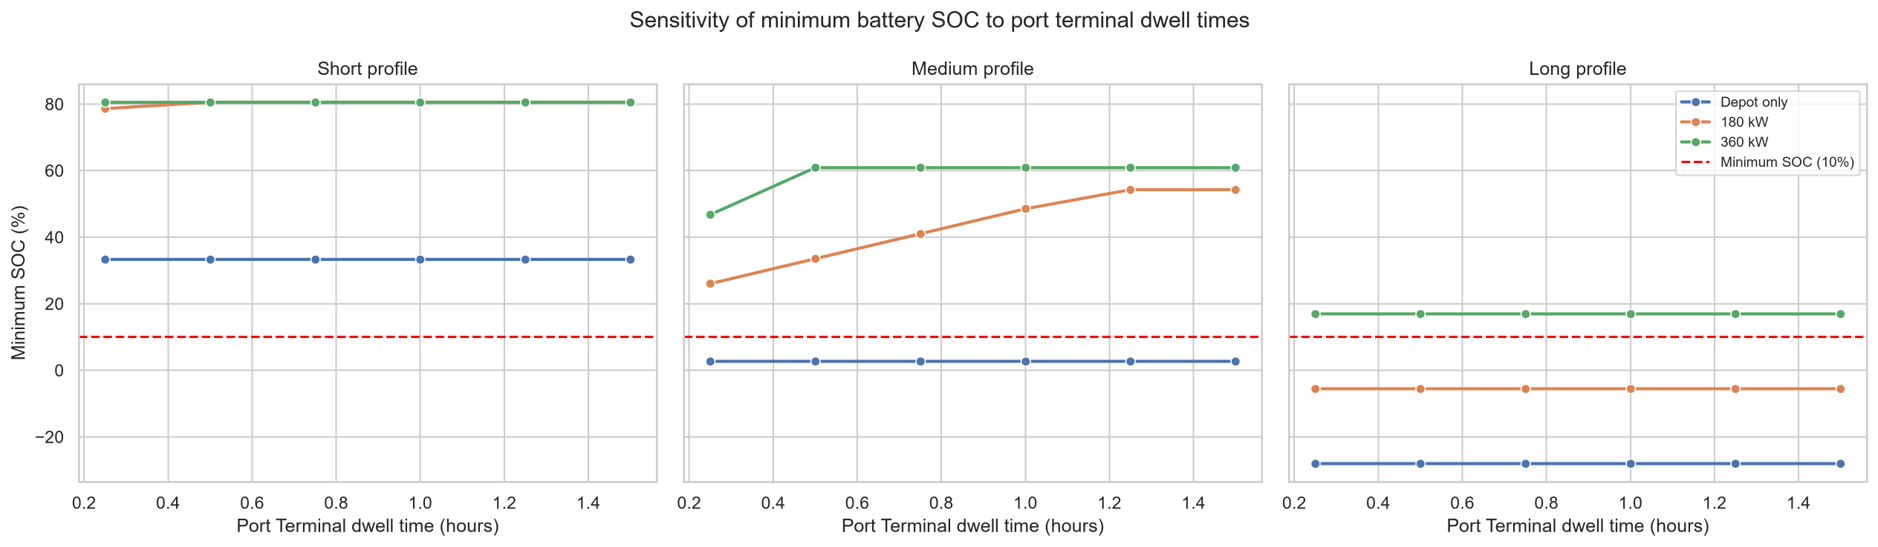

Figure 7. Sensitivity of minimum battery SOC to port terminal dwell time.

Figure 7 shows the impact of increasing port terminal dwell time from 0.25 to 1.5 hours. Short distance duties remain feasible under all charging configurations, with no significant improvement from longer dwell periods. For medium-distance duties, the minimum SOC with 180 kW charging increases from approximately 26% to 54.3%, while 360 kW charging reaches approximately 60.9% with a 0.50-hour dwell. In contrast, the long-distance duty shows no changes in minimum SOC because its operational schedule includes only one round a trip without intermediate port terminal charging opportunities.

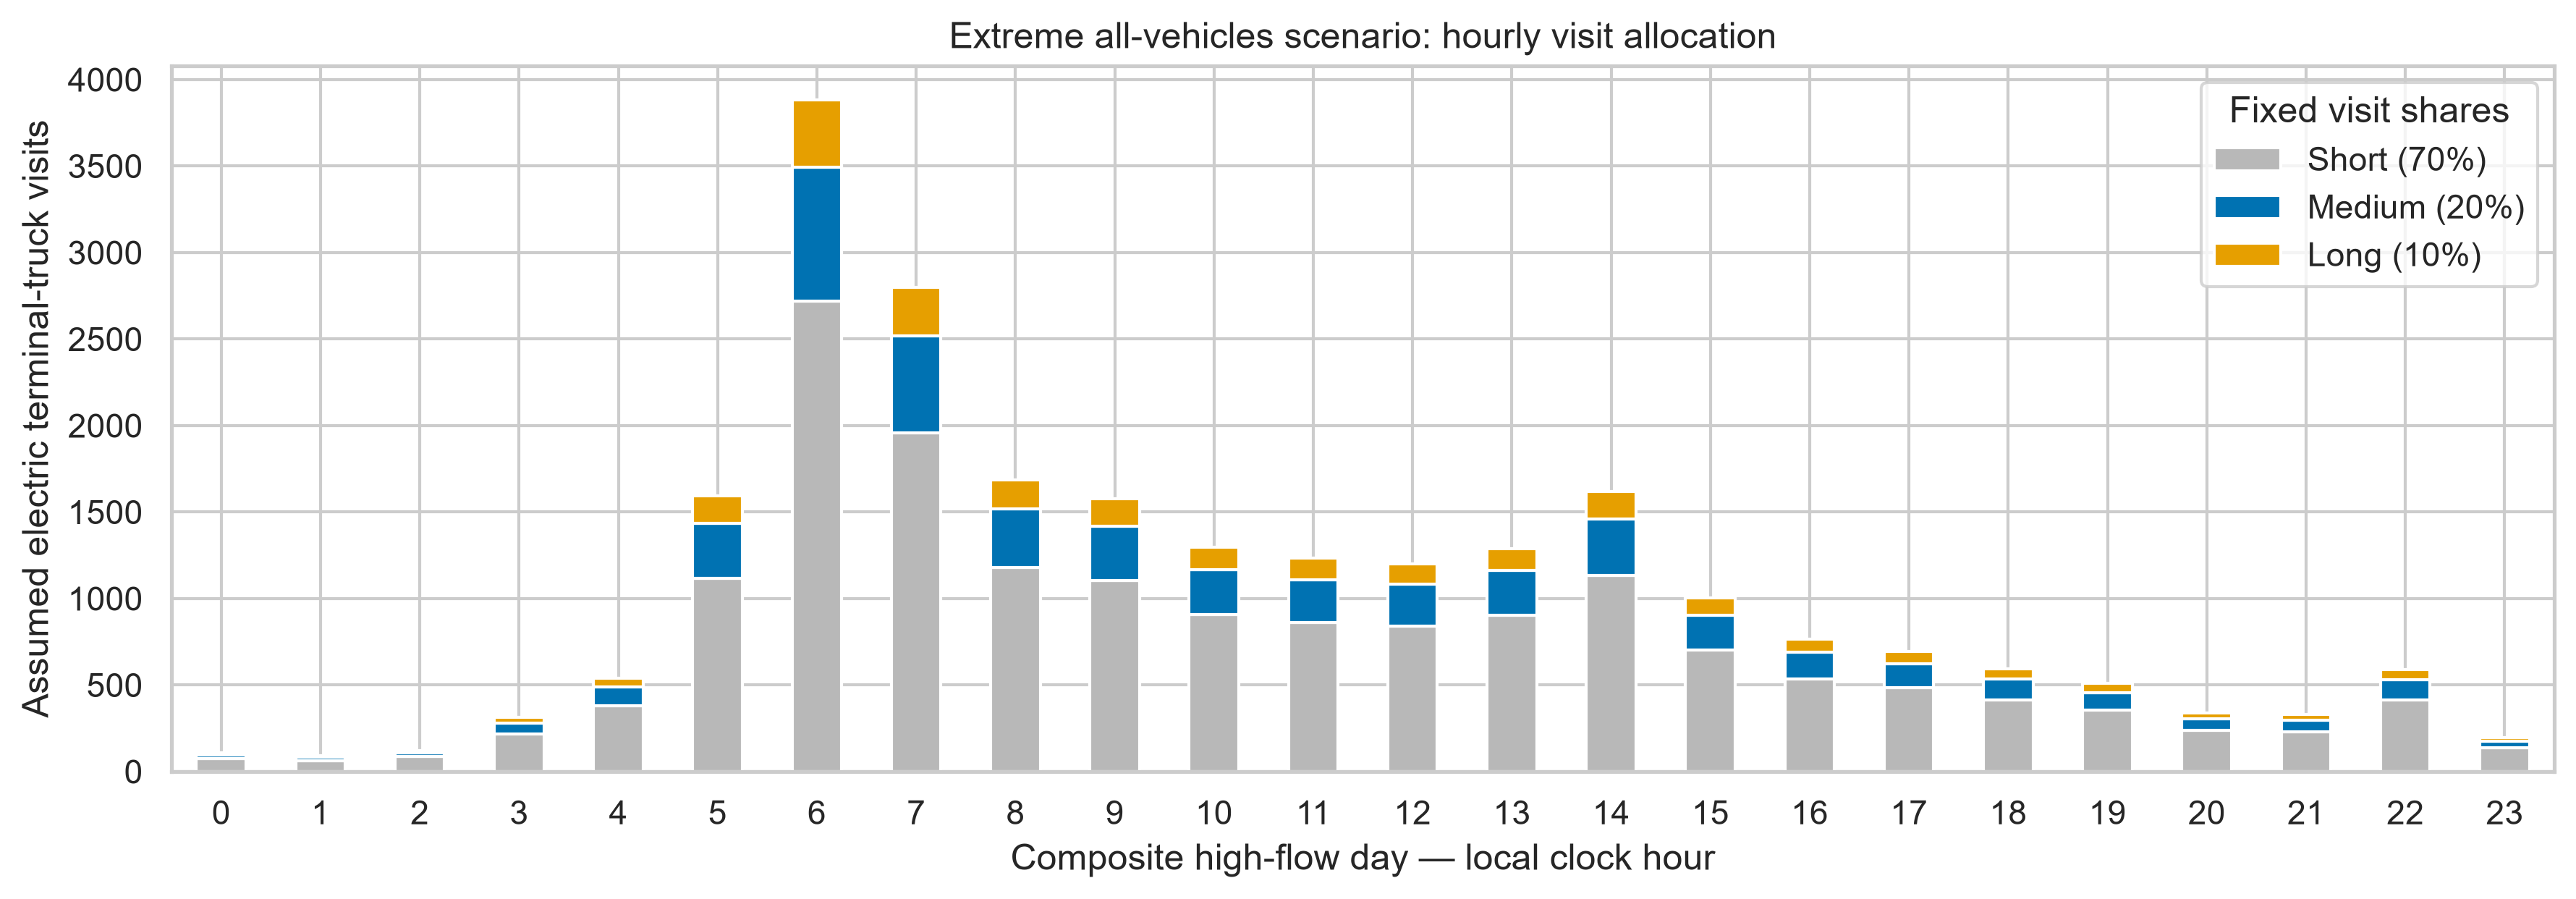

Figure 8. Extreme all-vehicles scenario: hourly visit allocation

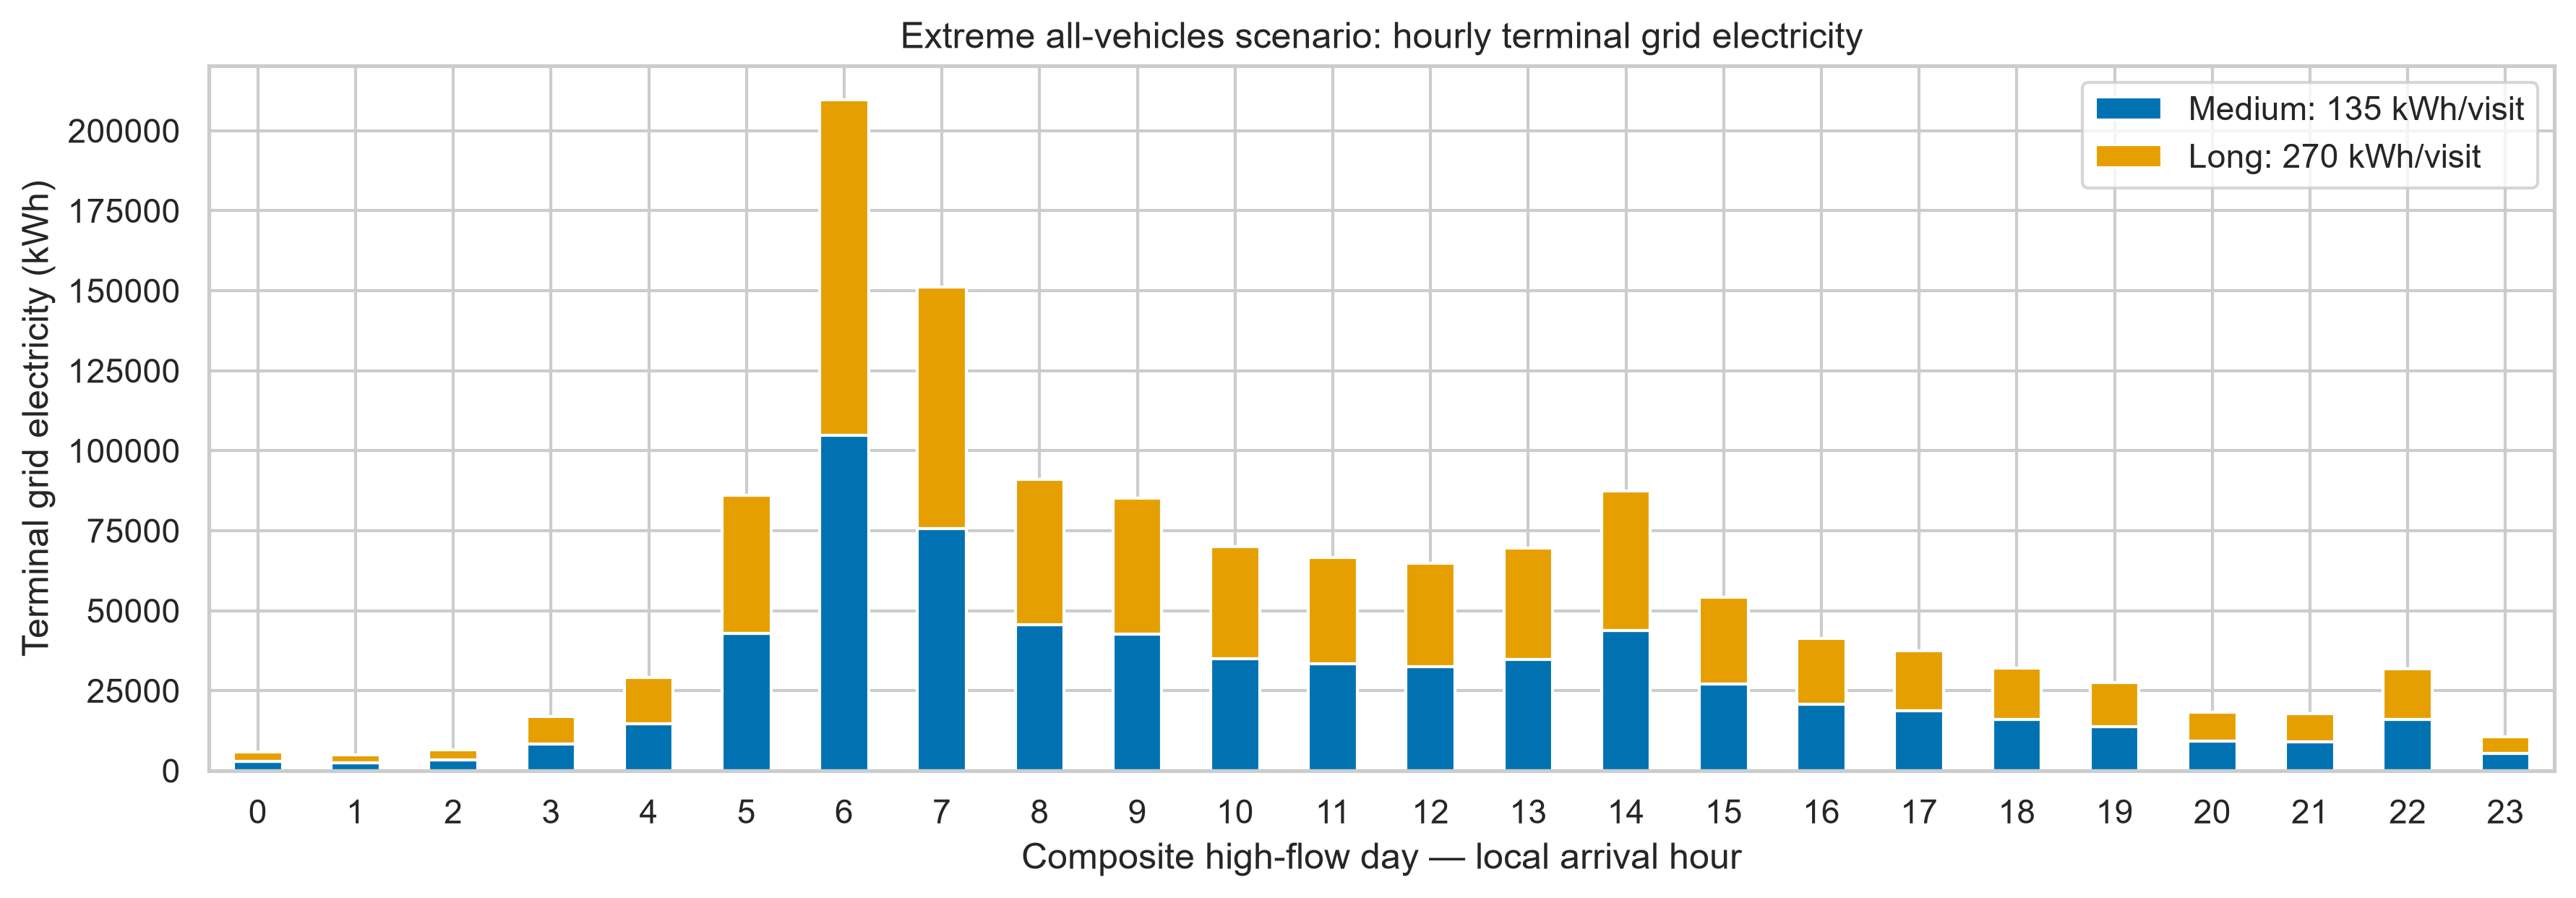

Figure 9. Extreme all-vehicles scenario: hourly terminal grid electricity.

Figures 8 and 9 illustrate the extreme all-vehicles scenario results for hourly truck visit allocations and corresponding terminal grid electricity demand across a high-flow traffic day. Applying a fixed operational profile distribution of 70% short, 20% medium, and 10% long visits, the hourly visit allocations peak sharply during morning hours (particularly between 06:00 and 08:00), mirroring the inbound traffic volume patterns. Consequently, the resulting terminal grid electricity demand—driven exclusively by medium (135 kWh per visit) and long (270 kWh per visit) operational profiles—reaches its maximum during these peak traffic hours, scaling proportionally with traffic flow to establish a clear baseline for worst-case charging infrastructure requirements.

# Conclusions


The simulation results indicate that the energy requirements of representative truck duties differ significantly across operational profiles. Short-distance duties can be fully supported by the baseline battery capacity, whereas medium- and long-distance duties exceed usable battery capacity, making intermediate opportunity charging necessary under baseline assumptions.

Regarding duty feasibility, overnight depot charging alone is sufficient for the short-distance profile. The medium-distance profile becomes feasible when supplemented with 180 kW opportunity charging, whereas the long-distance profile requires 360 kW opportunity charging.

These findings demonstrate that operational feasibility is governed not only by cumulative daily energy demand, but also by the spatial and temporal distribution of charging opportunities throughout the operational cycle.

Regarding repeatable daily feasibility, all configurations capable of completing their assigned duties successfully restored their initial state of charge (90% SOC) prior to the next departure. Consequently, overnight depot charging did not impose an additional operational constraint within the baseline simulation setup.

The sensitivity analysis confirms that operational feasibility is highly sensitive to energy consumption rates and charging window availability. While extended dwell periods enhance feasibility, their effectiveness is constrained by duty scheduling and charging power. Therefore, electric truck feasibility cannot be evaluated based on total distance alone; duties with similar daily energy requirements may require fundamentally different charging strategies depending on the frequency and duration of available charging windows.

Overall, this study provides a structured assessment of charging feasibility across three representative port-drayage operations serving the Port of Rotterdam (PoR). Within the simulated scope, depot-only charging satisfies short-distance operational requirements, while medium- and long-distance profiles require intermediate opportunity charging at distinct power levels. The sensitivity analysis provides detailed insights into how variations in consumption rates and dwell durations alter operational feasibility within the model boundaries. Combining controlled parameter sweeps with empirical DEXTER flow integration yields crucial insights into how operational variability and network-level arrival dynamics impact grid demand and charging infrastructure requirements.

# Discussion

These findings establish a foundation for scaling the current simulation framework toward a network-level assessment of charging infrastructure across the Port of Rotterdam (PoR). While the controlled parameter sweeps isolate individual variable sensitivities, integrating empirical arrival distributions from the DEXTER dataset demonstrates the critical impact of real-world traffic and flow variability on peak-hour charging demand. Future model iterations could build upon these empirical foundations to incorporate simultaneous multi-vehicle movements, terminal-specific charging demands, charger access constraints, and queuing dynamics. Integrating these factors will enable the framework to transition from single-duty feasibility to estimating the optimal count, capacity, and spatial allocation of chargers required for port-wide fleet electrification.

Several limitations should be considered when interpreting these results:

The simulation relies on three stylized operational profiles with fixed distances, travel speeds, and schedules. While effective for comparative analysis and complemented here by empirical DEXTER flow checks, these profiles do not capture the full operational heterogeneity of drayage fleets serving the PoR, such as traffic congestion, variable payloads, or randomized arrival distributions.

The model assumes constant energy consumption rates (1.7 kWh/km), constant charging power, and 100% charger availability. It excludes real-world disruptions such as charger downtime, queues, or detour overheads, which could reduce net energy recovery and compromise duty completion.

The current sensitivity sweep evaluates individual vehicle duties independently. It does not account for simultaneous charging concurrency across multiple vehicles, which is critical for sizing grid connection requirements and terminal transformer capacities.

# Contribution Statement



**Andrea De Felice**:

Drafted initial project context, objective and research questions and contributed to Python code for the Simulation and Modelling part



**Fernando Quiros Solano**:

Wrote Results, Conclusions, Discussion, and Read me file.


**Magdalini Karataraki**:  

Wrote and reviewed Final report and Read me, contributed to Python code for review, visualization and data analysis for worst case scenario as sensitivity

**Stella Nestori**:

Drafted initial project context and research questions

**Yiying Sandra Zhu Zhou**:

Wrote and reviewed Final report and Read me, contributed to Python code for review, visualization and sensitivity analysis


# References

European Comission. (2026). Heavy-duty vehicles: Council adopts targeted flexibility for manufacturers to comply with CO2 targets https://www.consilium.europa.eu/en/press/press-releases/2026/03/30/heavy-duty-vehicles-council-adopts-targeted-flexibility-for-manufacturers-to-comply-with-co2-targets/


European Commission. (2026). Lorries, buses and coaches. https://climate.ec.europa.eu/areas-action/transport-decarbonisation/road-transport/lorries-buses-and-coaches_en?utm_source=chatgpt.com


European Environment Agency. (2026, June 27). Transport and mobility. https://www.eea.europa.eu/en/topics/in-depth/transport-and-mobility



Nationaal Dataportaal Wegverkeer (NDW). (n.d.). DEXTER Open Data & Historical Traffic Database. Retrieved November 6, 2026, from https://dexter.ndw.nu/opendata/overview


Port of Rotterdam Authority. (2024, January 26). First charging station for electric trucks opened in the port of Rotterdam. https://www.portofrotterdam.com/en/news-and-press-releases/first-charging-station-for-electric-trucks-opened-in-the-port-of-rotterdam?utm_source=chatgpt.com

Smart Freight Centre (2024). Preliminary assessment of e-truck operational and economic viability: Drayage operations from and to the Port of Rotterdam https://smartfreightcentre.org/news/13311296



Volvo Trucks. (2021, November 29). How a good charging strategy can extend an electric truck’s range. VOLVO Group. https://www.volvotrucks.com/en-en/news-stories/insights/articles/2021/nov/How-a-good-charging-strategy-can-extend-an-electric-trucks-range.html


# AI Statement

We acknowledge the use of AI in preparing this submission. We used it for the following purposes: Refining language (grammar, vocabulary, clarity, and consistency in the report, ...).

**Fernando Quiros** used ChatGPT to assist in refining language, and academic writing in the Results, Discussion, and Conclusions section.

**Sandra Zhu Zhou** used ChatGPT to assist in refining language in report writing, as well as evaluating code structure and debugging errors within the Python simulation pipeline.

**Magdalini Karataraki** used Gemini to assist with language refinement, grammar correction, and syntax checking within the report's text, as well as evaluating code structure and debugging errors within the Python simulation pipeline.

**Stella Nestori** used ChatGPT to assist in refining language in report writing.

**Andrea De Felice** used ChatGPT to assist in refining language in report writing and evaluating code structure and debugging errors within the Python simulation pipeline.

We confirm that we have critically reviewed and verified all AI-assisted content, that the submitted work reflects our own understanding, and that we take full responsibility for its accuracy and originality.